## Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Potential waveforms

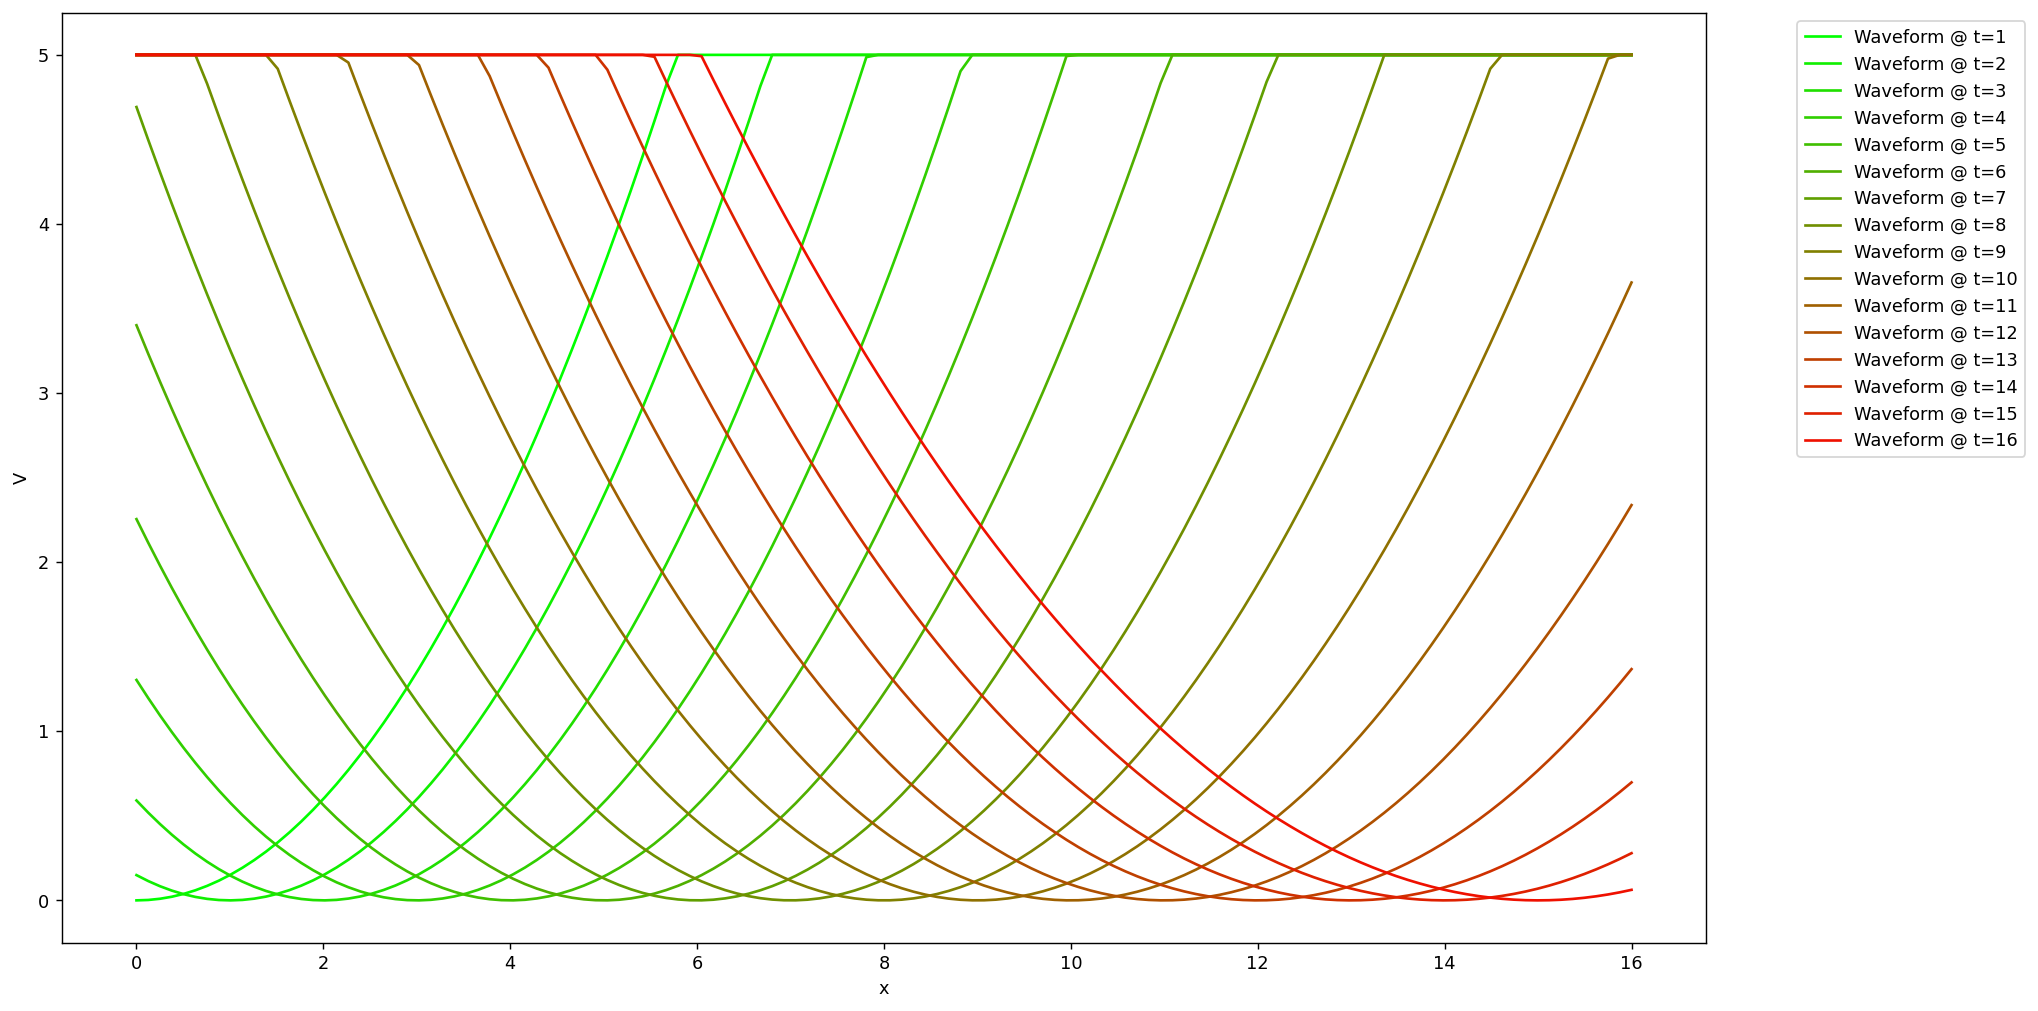

In [36]:
fig, ax = plt.subplots(figsize=(16,8), dpi=128)

x_fine = np.linspace(0, 16, 128)

waveform_list = []
for t in range(16):
    waveform_coarse = np.clip(0.15*np.abs(-t**2/16**2)*np.abs(x_fine-t), a_min=0, a_max=5)
    waveform_fine = np.clip(0.15*np.exp(-t**2/16**2)*np.pow(x_fine-t, 2), a_min=0, a_max=5)
    waveform_list.append(waveform_fine)
    
    plt.plot(x_fine, waveform_fine, c=(t/16, 1-t/16, 0), label=f"Waveform @ t={t+1}")

plt.xlabel("x")
plt.ylabel("V")
legend = plt.legend()
legend.set_in_layout(False)
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.tight_layout()

plt.show()

## Ion trajectories - static waveforms

In [37]:
def verlet(m, q, pos, vel, acc, dt, grad_V):
    new_pos = pos + vel * dt + 0.5 * acc * dt * dt
    
    grad_V = grad_V(new_pos)

    new_acc = -q * grad_V/m

    new_vel = vel + 0.5 * (acc + new_acc) * dt

    return m, q, new_pos, new_vel, new_acc, dt

In [38]:
m = 1#1E-3
q = 1#1E-3
pos = np.array([0, 0, 1E1])
vel = np.array([0, 0, 0])
acc = np.array([0, 0, 0])
dt = 1E-3

In [39]:
# fig, ax = plt.subplots(dpi=128)

# plt.cla()

# V_0 = 10000

# N_it = 10000

# grad_V_label_list = ["Constant potential", "Linear potential", "Quadratic potential"]
# grad_V_list = [lambda pos : np.array([0, 0, V_0]), lambda pos : np.array([0, 0, V_0 + pos[-1]]), lambda pos : np.array([0, 0, V_0 + pos[-1]**2])]

# for grad_V_label, grad_V in zip(grad_V_label_list, grad_V_list):
#     pos_list = [pos]
#     vel_list = [vel]
#     acc_list = [acc]
#     for it in range(N_it):
#         _, _, new_pos, new_vel, new_acc, _ = verlet(m, q, pos_list[-1], vel_list[-1], acc_list[-1], dt, grad_V)
#         pos_list.append(new_pos)
#         vel_list.append(new_vel)
#         acc_list.append(new_acc)
    
#     pos_list = np.array(pos_list) - pos

#     print("a", N_it+1, len(pos_list[:, -1]))
    
#     plt.scatter(range(N_it+1), pos_list[:, -1], label=grad_V_label)

# plt.title("Trajectories w/ Velocity Verlet")
# plt.xlabel("Timestep #")
# plt.ylabel("Displacement")

# plt.legend()

## Ion transjectories - dynamic waveforms

/tmp/ipykernel_69422/4172085648.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


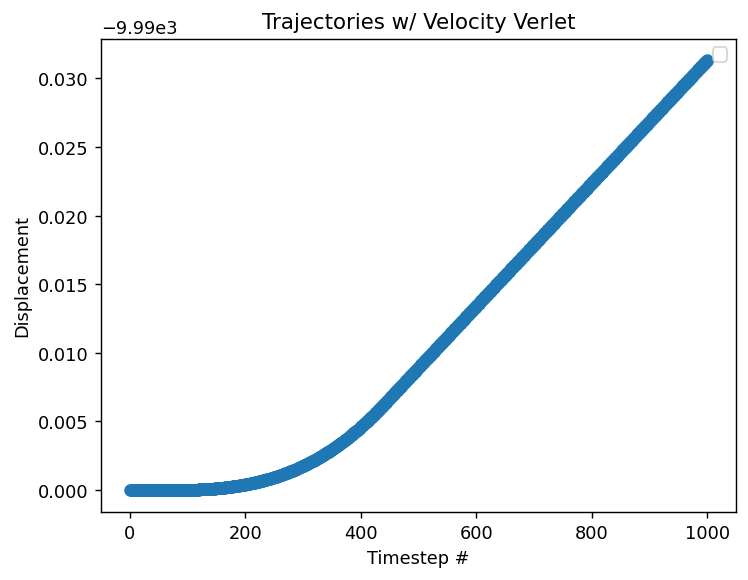

In [40]:
fig, ax = plt.subplots(dpi=128)

plt.cla()

N_it = 1000

pos_list = [pos]
vel_list = [vel]
acc_list = [acc]

for it in range(N_it):
    waveform_idx = int(np.floor(it/N_it * len(waveform_list)))
    V = waveform_list[waveform_idx]
    def grad_V(pos):
        grad_V_list = list(np.diff(V)) + [0]
        grad_V_val = np.interp(pos, x_fine, grad_V_list)
        return grad_V_val
    
    _, _, new_pos, new_vel, new_acc, _ = verlet(m, q, pos_list[-1], vel_list[-1], acc_list[-1], dt, grad_V)
    pos_list = list(pos_list)
    vel_list = list(vel_list)
    acc_list = list(acc_list)
    pos_list.append(new_pos)
    vel_list.append(new_vel)
    acc_list.append(new_acc)
    
    pos_list = np.array(pos_list) - pos
    
plt.scatter(x=range(N_it+1), y=pos_list[:, -1])

plt.title("Trajectories w/ Velocity Verlet")
plt.xlabel("Timestep #")
plt.ylabel("Displacement")

plt.legend()